# Data analysis
- Imports castrated data from '20241203_Fused_Control_homeo_castre.csv'
- Produces csv files used for analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")
import clones


plt.rcParams['figure.figsize'] = (4, 3)


def sefrac(f, n):
    fa = np.array(f)
    na = np.array(n)
    return np.sqrt(fa*(1-fa)/na)

def laggedevent(movebytimeclone, dBas1, dSup1, dBas2, dSup2):
    ntimes  = np.shape(movebytimeclone)[1]
    nclones = np.shape(movebytimeclone)[0]
    
    event = np.zeros((ntimes - 2, ntimes - 1), dtype = 'int32')

    for t in range(ntimes - 1):
        for c in range(nclones):
            for n in range(1,ntimes - 1):
                if t + n < ntimes:
                    event[n-1, t] += (movebytimeclone[c, t, dBas1, dSup1] == 1) and (movebytimeclone[c, t+n, dBas2, dSup2] == 1)
    return event

def evenbias(clonesize, singletime = False):
    #Mathematica:  p = 1/m; Simplify[Sum[p*(1 - p)^(2*k - 1), {k, 1, Infinity}]]
    #We need a way of assessing the error on even bias
    
    if singletime == True:
        clonesize = np.array(clonesize[np.array(clonesize) > 0])
        fracEven = 1 - np.mean(clonesize % 2) 
        avSize    = np.mean(clonesize)
        fracexpect  = (avSize - 1)/(2*avSize - 1)
        
        return (fracEven - fracexpect)/(1 - fracexpect)
    else:
        clonesize = [np.array(cst[np.array(cst) > 0]) for cst in clonesize]
        avSize = np.array([np.mean(cst) for cst in clonesize])
        fracEven = np.array([1 - np.mean(cst % 2) for cst in clonesize])
        
    fracexpect  = (avSize - 1)/(2*(avSize) - 1)
    return (fracEven - fracexpect)/(1 - fracexpect)


'''  
    Compute the counts tensor for experiments
'''

def extend_livesize(livesize):
    nclones = np.shape(livesize)[0]
    time0 = np.zeros((nclones, 1, 2), dtype = 'int32')
    time0[:,0,0] = 1
    return np.concatenate((time0, livesize), axis = 1)



def get_allmoves(livesize, full_timelapse, use_df = False):
    ''' 
        Define allmoves in the following way:
        allmoves[time, bas_t-1, sup_t-1, bast, bast, dSup2, mouse, clone type]
        
        We only specify moves starting from surviving clone numbers
        
        This is convenient for specifying likelihood
        
        Then we specify the unique transitions which occur in the data
    '''
    
    full_livesize = extend_livesize(livesize)

    
    full_timelapse['max_tot'] = np.max(np.sum(full_livesize,2),1)
    
    full_timelapse['ctype'] = ''
    full_timelapse.loc[full_timelapse['max_tot'] >= 3, 'ctype'] = 'S'
    full_timelapse.loc[full_timelapse['max_tot'] == 2, 'ctype'] = 'T'
    full_timelapse.loc[full_timelapse['max_tot'] == 1, 'ctype'] = 'D'
    
    mice = full_timelapse['mice_ID'].unique()
    max_bas = full_livesize[:,:,0].max() + 1
    max_sup = full_livesize[:,:,1].max() + 1
    
    ntimes = np.shape(full_livesize)[1] - 1
    
    ctypes = ['S', 'T', 'D']
    ntypes  = len(ctypes)
   
    allmoves = np.zeros((ntimes, max_bas, max_sup, max_bas, max_sup, ntypes, len(mice)), dtype = 'int32')

    for m in range(len(mice)):
        for ct in range(len(ctypes)):
            cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
            for c in range(len(cids)):
                for t in range(ntimes):
                    bas0 = full_livesize[cids[c],t,0]
                    sup0 = full_livesize[cids[c],t,1]
                    bas1 = full_livesize[cids[c],t+1,0]
                    sup1 = full_livesize[cids[c],t+1,1]
                    if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:
                        allmoves[t, bas0, sup0, bas1, sup1, ct, m] += 1
            
    allmoves_bas = np.sum(allmoves, axis = (2,4))
             
    if use_df:
        all_moves     = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'supra0', 'basal1', 'supra1', 'count'])
        all_moves_bas = pd.DataFrame(columns = ['sex', 'mice_ID', 'time', 'ctype', 'basal0', 'basal1', 'count'])

        for m in range(len(mice)):
            for ct in range(len(ctypes)):
                cids = np.where((full_timelapse['mice_ID'] == mice[m]) & (full_timelapse['ctype'] == ctypes[ct]))[0]
                for t in range(ntimes):
                    unqclones = np.unique(full_livesize[cids,t:t+2,:], axis = 0)
                    for u in unqclones:
                        bas0 = u[0,0]
                        sup0 = u[0,1]
                        bas1 = u[1,0]
                        sup1 = u[1,1]
                        if bas0 > 0 and sup0 >= 0 and bas1 >= 0 and sup1 >= 0:                    
                            to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'supra0': sup0, 'basal1': bas1, 'supra1': sup1, 'count': allmoves[t, bas0, sup0, bas1, sup1, ct, m]}
                            all_moves = pd.concat([all_moves, pd.DataFrame([to_append])], ignore_index=True)  
                            
                    unqbas = np.unique(full_livesize[cids,t:t+2,0], axis = 0)
                    for u in unqbas:
                        bas0 = u[0]
                        bas1 = u[1]
                        if bas0 > 0 and bas1 >= 0:                    
                            to_append = {'sex': mice[m][0], 'mice_ID': mice[m], 'time': t, 'ctype': ctypes[ct], 'basal0': bas0, 'basal1': bas1, 'count': allmoves_bas[t, bas0, bas1, ct, m]}
                            all_moves_bas = pd.concat([all_moves_bas, pd.DataFrame([to_append])], ignore_index=True)              
        
        return all_moves, all_moves_bas
    else:
        return allmoves, allmoves_bas
        


import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)

/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_castre.pkl


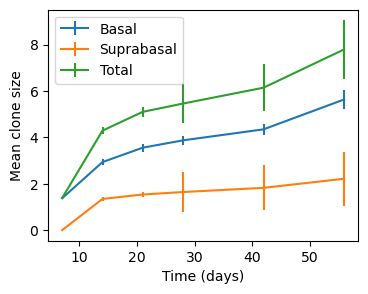

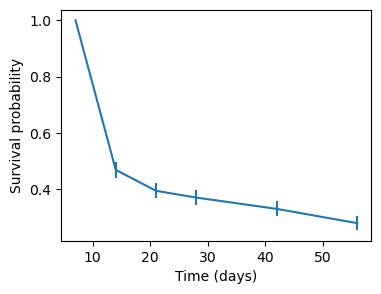

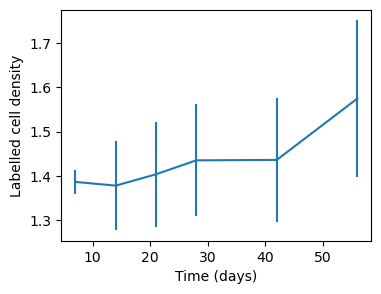

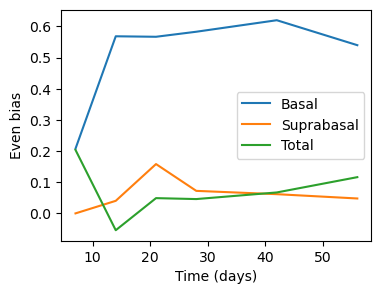

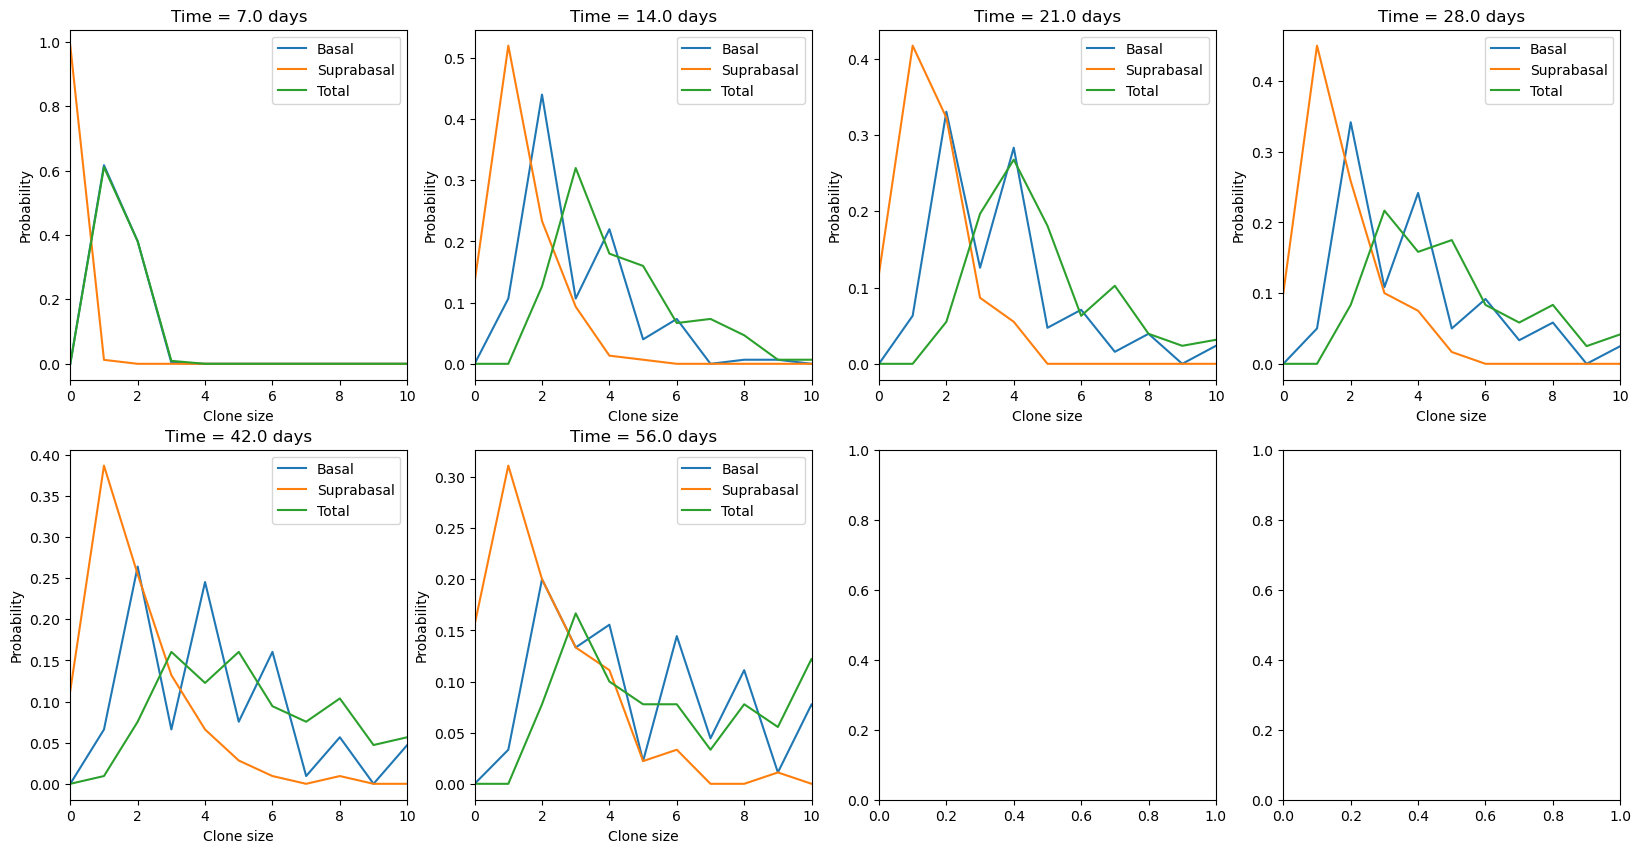

In [2]:
# Control data
filename = './20241203_Fused_Control_homeo_castre.csv'

miss_flag = -100

alldata = pd.read_csv(filename, sep=';')
alldata['sex'] = [m[0] for m in alldata['mice_ID'].values]
mice = list(alldata['mice_ID'].unique())
times = list(alldata['temps'].unique())
bas_names = ['D' + str(t) + '.basal' for t in times]
sup_names = ['D' + str(t) + '.supra' for t in times]
time_names = bas_names + sup_names
allclones = alldata['clone'].unique()

#Time-course data
full_timelapse = pd.DataFrame(columns = ['sex', 'mice_ID', 'clone', 'cat'] + time_names)

for c in allclones:
    clone_data = alldata.query('clone ==' + str(c)).copy()
    assert(len(clone_data['mice_ID'].unique()) == 1)
    #assert(len(clone_data['cat'].unique()) == 1)
    if len(clone_data['cat'].unique()) > 1:
        print('Error', c, clone_data['mice_ID'])
    clone_data.fillna(miss_flag, inplace=True)
    bas_data = {'D' + str(clone_data.temps.values[i]) + '.basal': int(clone_data.basal.values[i]) for i in range(len(clone_data))}
    sup_data = {'D' + str(clone_data.temps.values[i]) + '.supra': int(clone_data.supra.values[i]) for i in range(len(clone_data))}
    to_append = {'sex': clone_data['sex'].values[0], 'mice_ID': clone_data['mice_ID'].values[0], 'clone': c, 'cat': clone_data['cat'].values[0], **bas_data, **sup_data}
    full_timelapse = pd.concat([full_timelapse, pd.DataFrame([to_append])], ignore_index=True)

full_timelapse.fillna(miss_flag, inplace=True)

#Combined data
livesize = np.zeros((len(allclones), len(times), 2), dtype = 'int32')
livesize[:,:,0] = np.array(full_timelapse[bas_names].values, dtype = 'int32')
livesize[:,:,1] = np.array(full_timelapse[sup_names].values, dtype = 'int32')
lcs = clones.lanalysis(livesize, tvals = times, containsBasal = True)

full_timelapse.fillna(miss_flag, inplace=True)

all_moves, all_moves_bas = get_allmoves(livesize, full_timelapse, True)

data = {}
data['ctrBasalsize'] = lcs.av_bas_cs
data['ctrSuprasize'] = lcs.av_sup_cs
data['ctrTotalsize'] = lcs.av_tot_cs
data['ctrBasalEvenbias'] = lcs.ev_bas_cs
data['ctrSupraEvenbias'] = lcs.ev_sup_cs
data['ctrTotalEvenbias'] = lcs.ev_tot_cs

data['livesize'] = livesize
data['ctrjointpdf'] = lcs.joint_pdf

data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

data['all_moves'] = lcs.allmoves()
data['all_moves_bas'] = lcs.allmoves_bas()

data['ct_all_moves'] = all_moves
data['ct_all_moves_bas'] = all_moves_bas


cpdf = np.zeros((len(times), 3, np.max(lcs.tot_ls) + 2))
cpdf[:,0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
cpdf[:,1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
cpdf[:,2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

data['ctrpdf'] = cpdf

data['surprob'] = lcs.pers
data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
data['lcd']     = lcs.lcd
data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
data['nallc'] = lcs.non_missing
data['ctrNsamples'] = lcs.nsur

data['ctrTimeClonesize'] = lcs.tvals



save_object(data,    'data_castre.pkl')
print('Saved to: ' + 'data_castre.pkl')

plt.figure()
plt.errorbar(lcs.tvals[lcs.av_bas_cs > 0], lcs.av_bas_cs[lcs.av_bas_cs > 0], lcs.se_bas_cs[lcs.av_bas_cs > 0])
plt.errorbar(lcs.tvals[lcs.av_sup_cs > 0], lcs.av_sup_cs[lcs.av_sup_cs > 0], lcs.se_sup_cs[lcs.av_sup_cs > 0])
plt.errorbar(lcs.tvals[lcs.av_tot_cs > 0], lcs.av_tot_cs[lcs.av_tot_cs > 0], lcs.se_tot_cs[lcs.av_tot_cs > 0])    
plt.legend(['Basal', 'Suprabasal', 'Total'])
plt.xlabel('Time (days)')
plt.ylabel('Mean clone size')   
plt.show()

plt.figure()
plt.errorbar(lcs.tvals, lcs.pers, np.sqrt(lcs.pers*(1-lcs.pers)/lcs.non_missing))
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')
plt.show()

plt.figure()
plt.errorbar(lcs.tvals, lcs.lcd, lcs1.se_bas_cs)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')
plt.show()

plt.figure()
plt.plot(lcs.tvals, lcs.ev_bas_cs, label = 'Basal')
plt.plot(lcs.tvals, lcs.ev_sup_cs, label = 'Suprabasal')
plt.plot(lcs.tvals, lcs.ev_tot_cs, label = 'Total')  
plt.legend()  
plt.xlabel('Time (days)')
plt.ylabel('Even bias')
plt.legend()
plt.show()

fig, axs = plt.subplots(2, 4, figsize=(20, 10))

for t in range(len(lcs.tvals)):
    xx = t // 4
    yy = t % 4
    axs[xx,yy].plot(cpdf[t,:,:].T)
    axs[xx,yy].legend(['Basal', 'Suprabasal', 'Total'])
    axs[xx,yy].set_xlabel('Clone size')
    axs[xx,yy].set_ylabel('Probability')
    axs[xx,yy].set_xlim([0, 10])
    axs[xx,yy].set_title('Time = ' + str(lcs.tvals[t]) + ' days')
plt.show()

/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_M24_castre.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_M25_castre.pkl


/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/joelh/miniforge3/envs/tisspy/lib/python3.12/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saved to: data_M26_castre.pkl


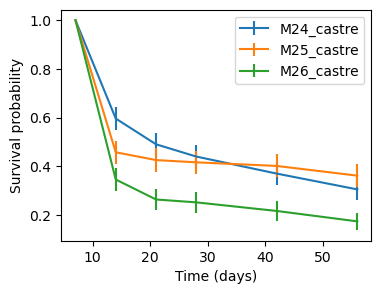

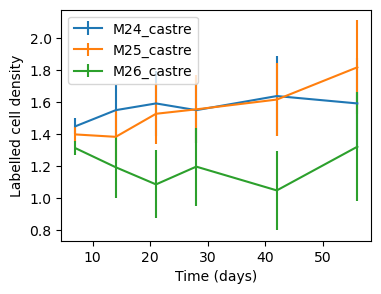

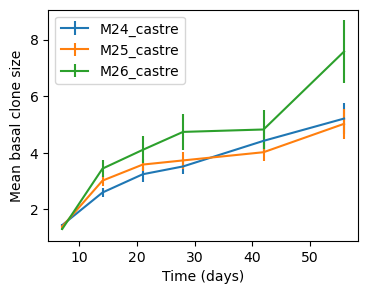

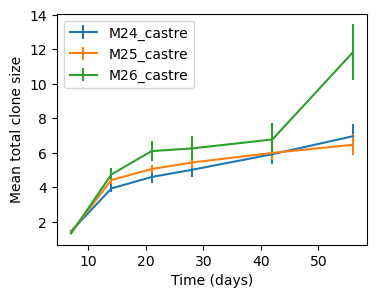

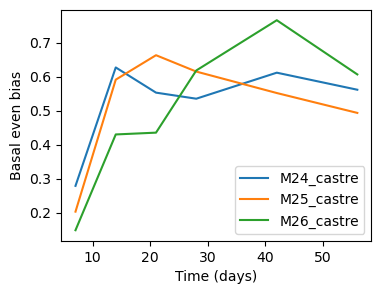

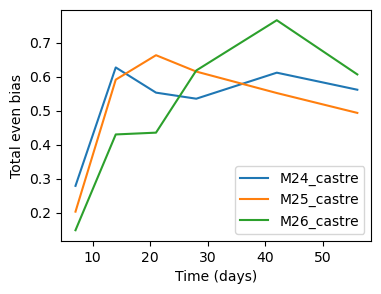

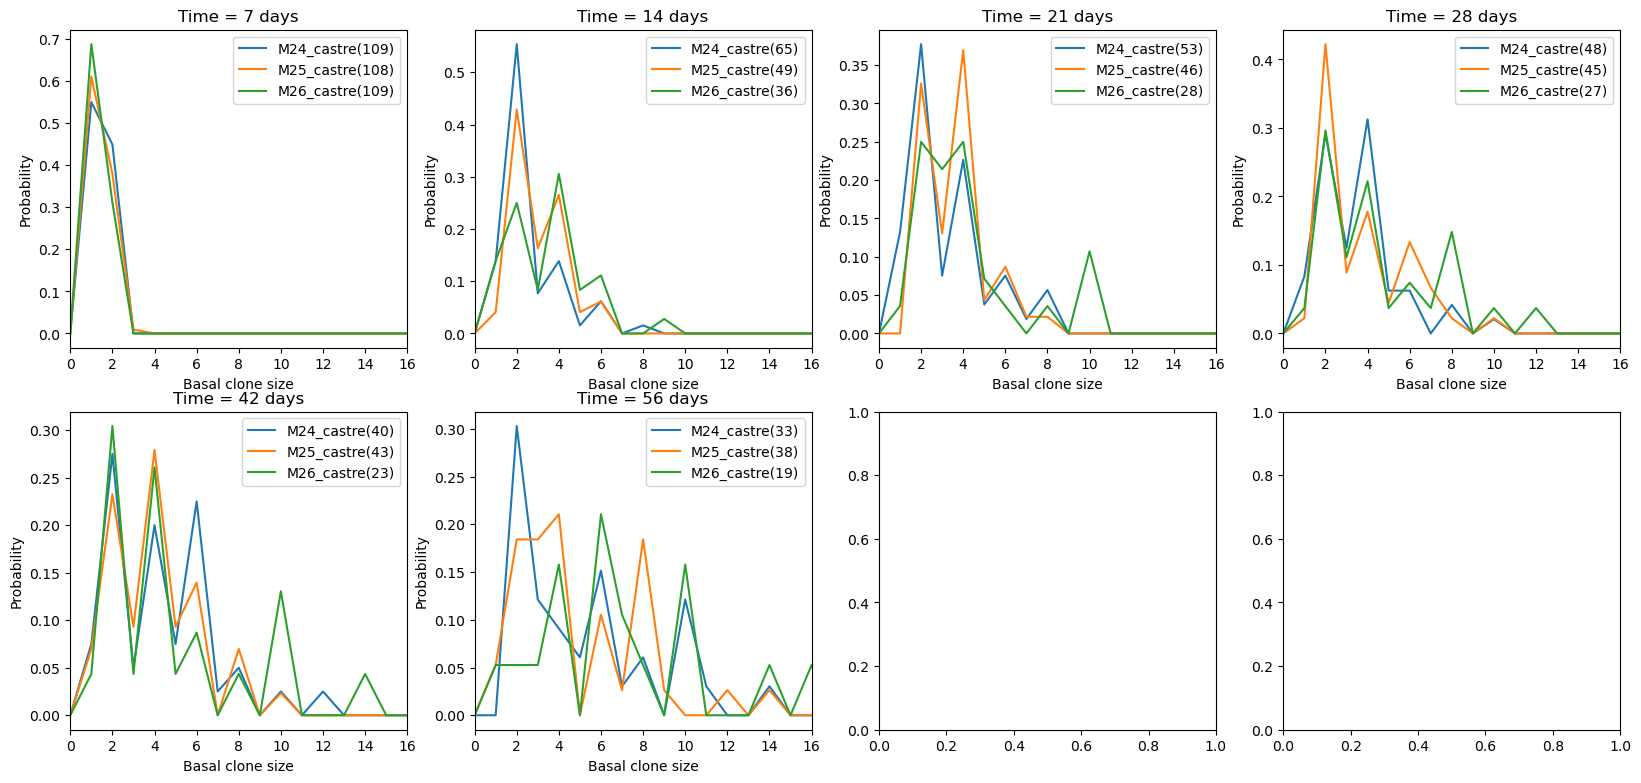

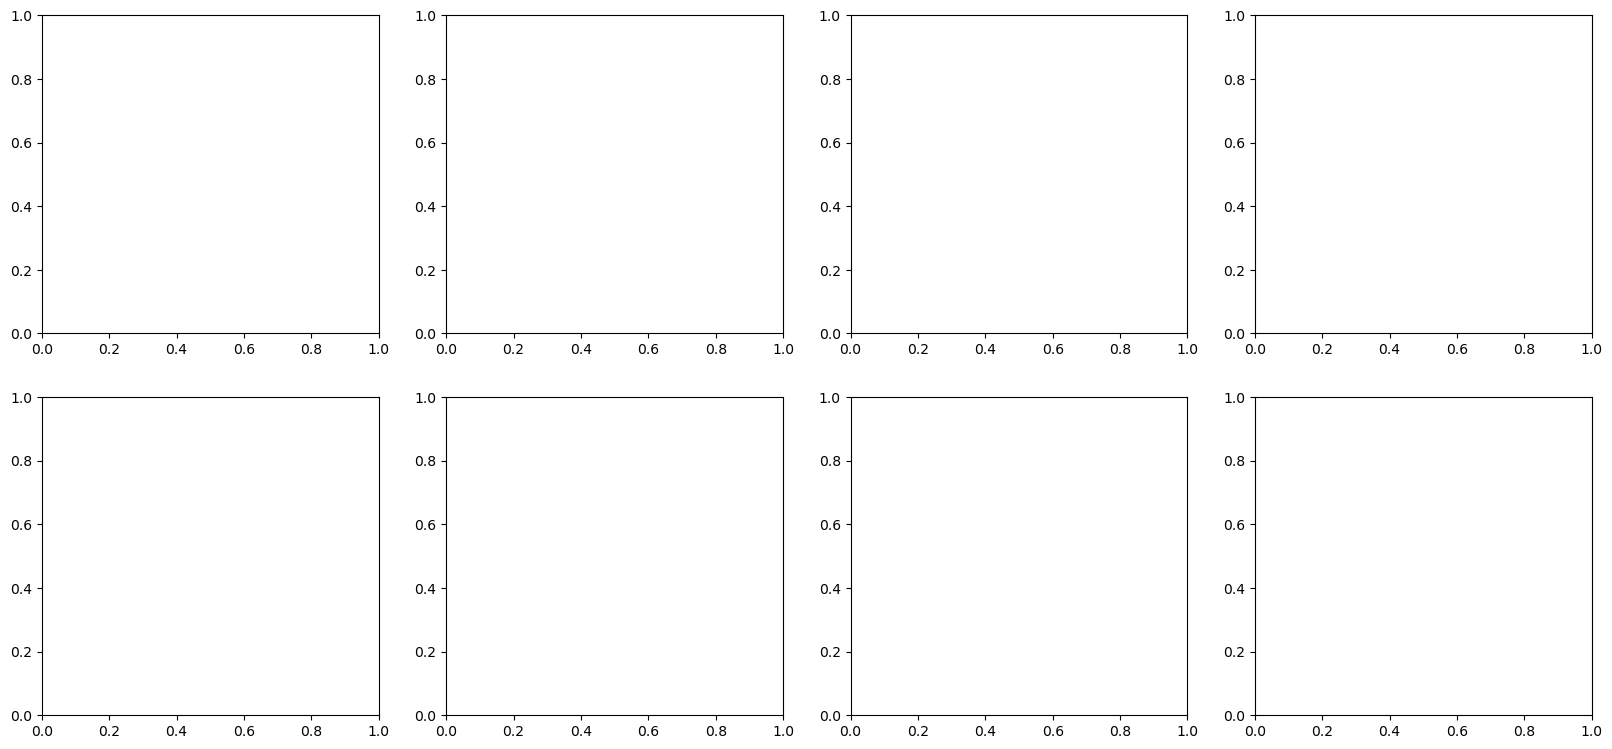

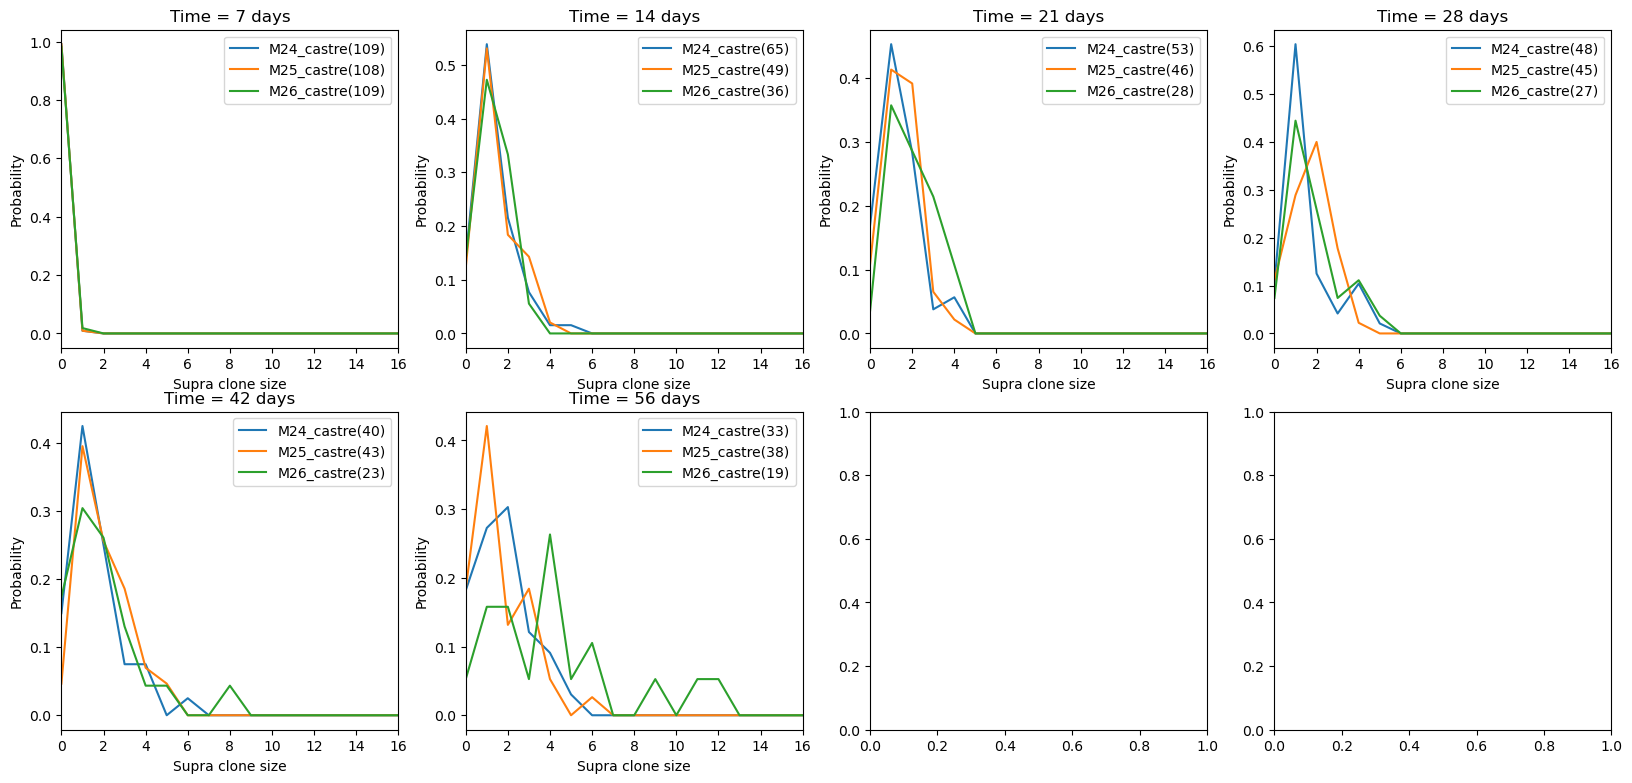

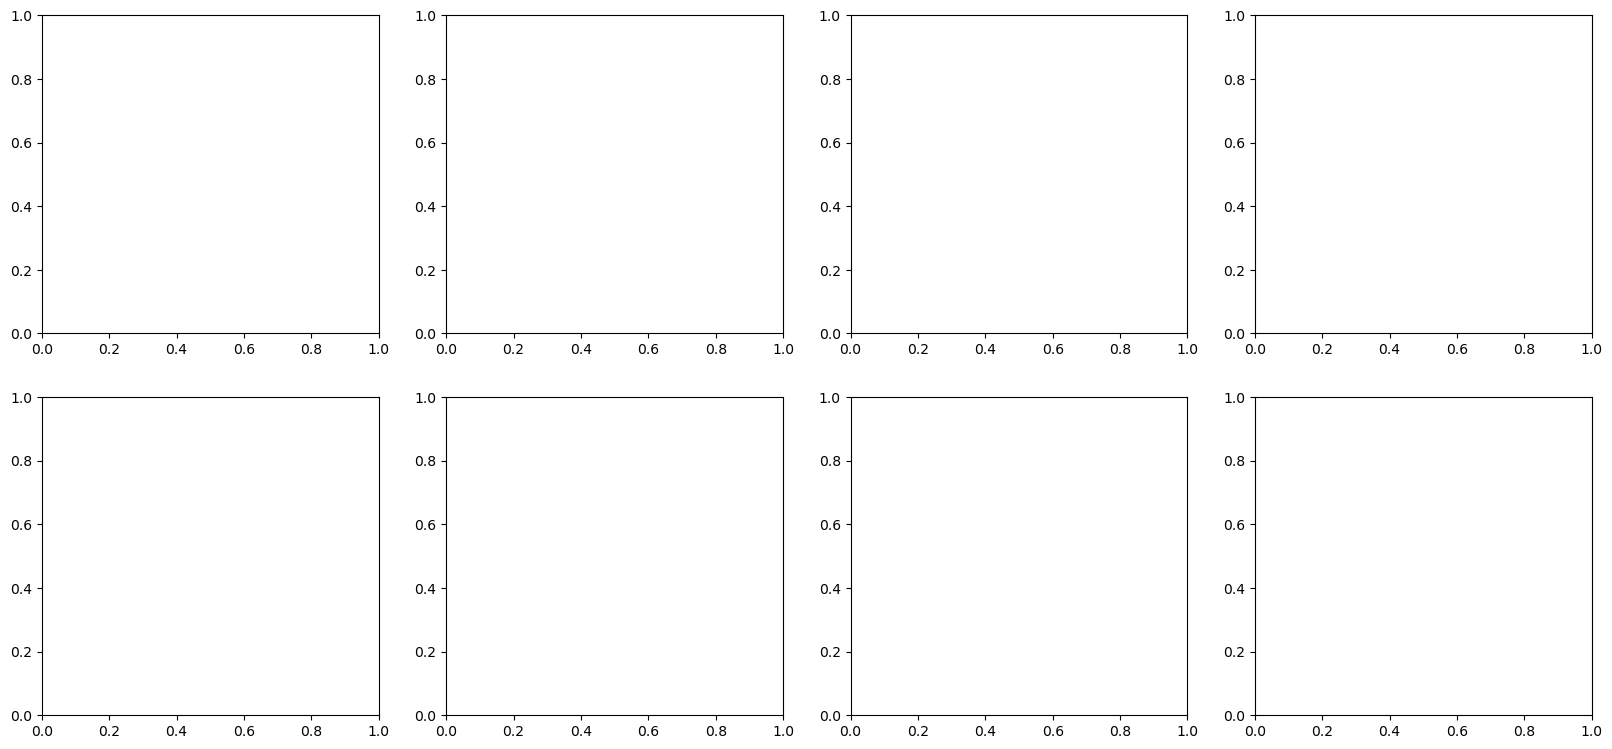

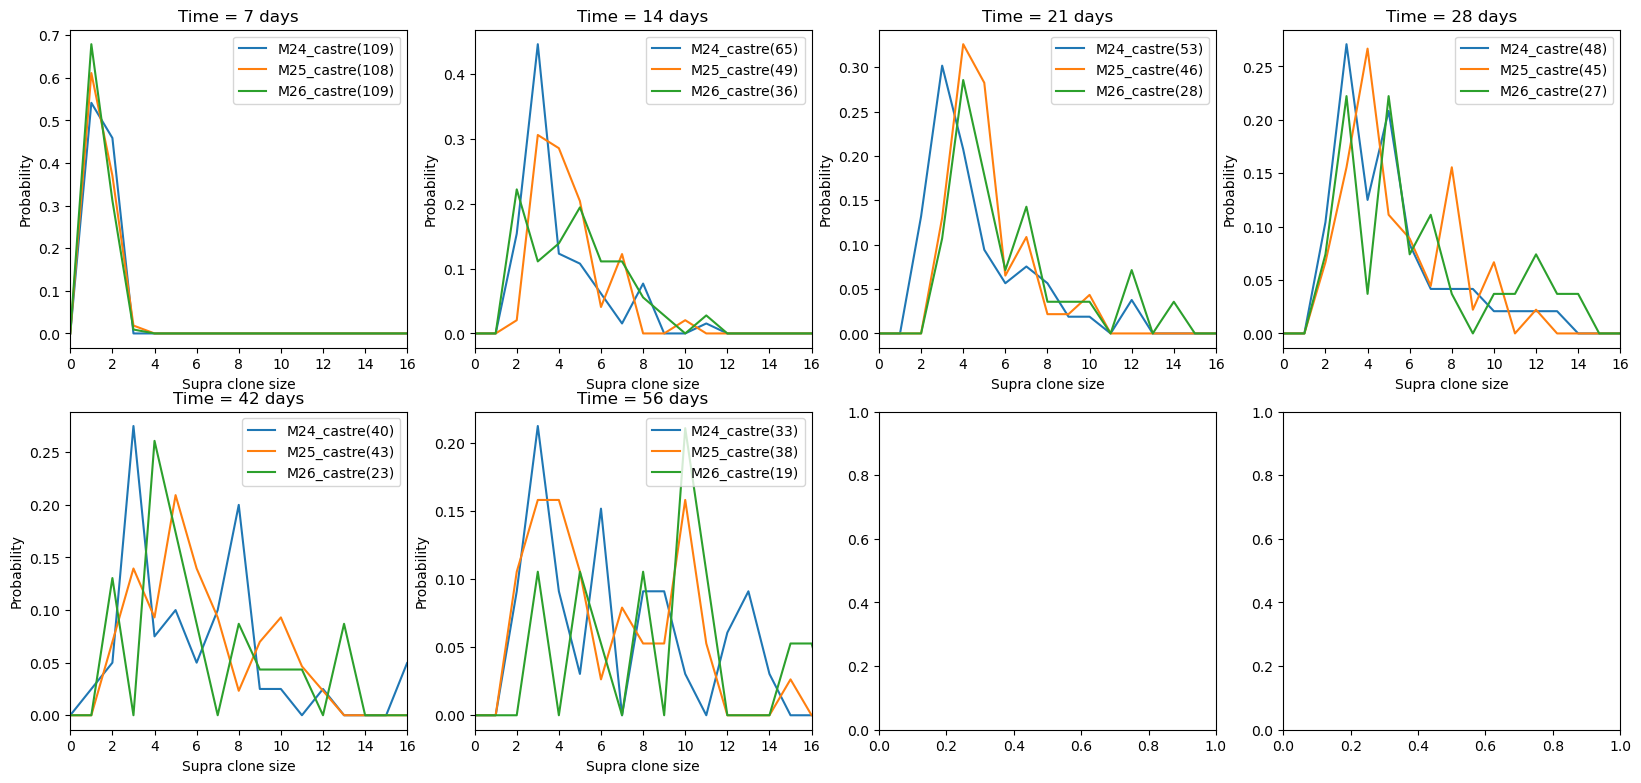

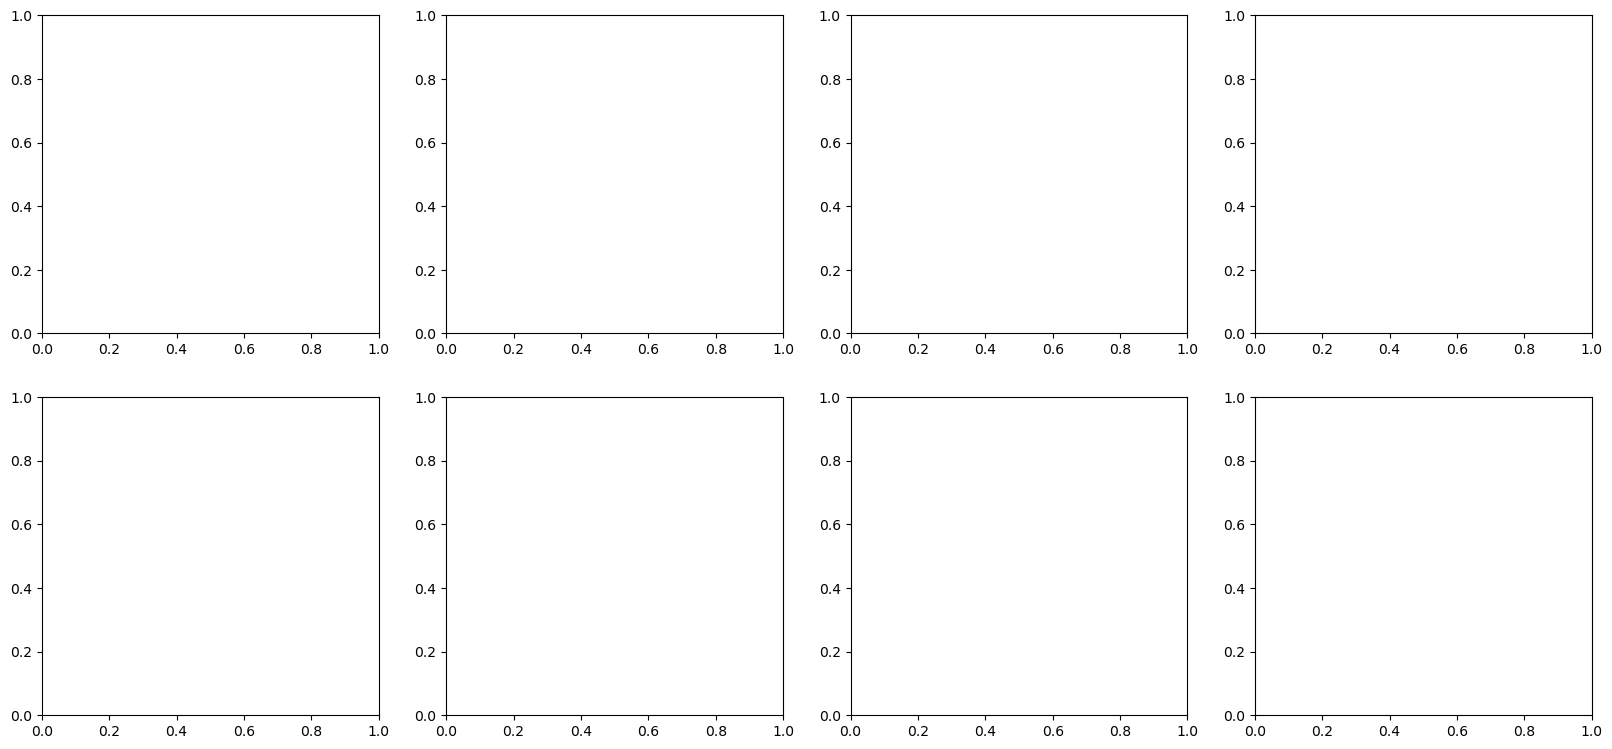

In [3]:
#Mouse-by-mouse data

for mid in mice:        
    sub_timelapse = full_timelapse[full_timelapse['mice_ID'] == mid]
    livesize = np.zeros((len(sub_timelapse), len(times), 2), dtype = 'int32')
    livesize[:,:,0] = np.array(sub_timelapse[bas_names].values, dtype = 'int32')
    livesize[:,:,1] = np.array(sub_timelapse[sup_names].values, dtype = 'int32')
    
    inctimes = np.max(np.min(livesize,2),0) >= 0
    livesize = livesize[:, inctimes, :]
    lcs = clones.lanalysis(livesize, tvals = np.array(times)[inctimes], containsBasal = True)


    data = {}
    data['ctrBasalsize'] = lcs.av_bas_cs
    data['ctrSuprasize'] = lcs.av_sup_cs
    data['ctrTotalsize'] = lcs.av_tot_cs
    data['ctrBasalEvenbias'] = lcs.ev_bas_cs
    data['ctrSupraEvenbias'] = lcs.ev_sup_cs
    data['ctrTotalEvenbias'] = lcs.ev_tot_cs

    data['livesize'] = livesize
    data['ctrjointpdf'] = lcs.joint_pdf

    data['ctrSDBasalsize'] = lcs.boot('av_bas_cs', calc = 'se') #lcs.se_bas_cs
    data['ctrSDSuprasize'] = lcs.boot('av_sup_cs', calc = 'se') #lcs.se_sup_cs
    data['ctrSDTotalsize'] = lcs.boot('av_tot_cs', calc = 'se') #lcs.se_tot_cs
    data['ctrSDBasalEvenbias'] = lcs.boot('ev_bas_cs', calc = 'se')
    data['ctrSDSupraEvenbias'] = lcs.boot('ev_sup_cs', calc = 'se')
    data['ctrSDTotalEvenbias'] = lcs.boot('ev_tot_cs', calc = 'se')

    data['all_moves'] = lcs.allmoves()
    data['all_moves_bas'] = lcs.allmoves_bas()

    cpdf = np.zeros((np.sum(inctimes), 3, np.max(lcs.tot_ls) + 2))
    cpdf[:,0, :lcs.bas_pdf().shape[1]] = lcs.bas_pdf()
    cpdf[:,1, :lcs.sup_pdf().shape[1]] = lcs.sup_pdf()
    cpdf[:,2, :lcs.tot_pdf().shape[1]] = lcs.tot_pdf()

    data['ctrpdf'] = cpdf

    data['surprob'] = lcs.pers
    data['SDsurprob'] = lcs.boot('pers', calc = 'se')  #sefrac(lcs.pers, lcs.non_missing)


    lcs1 = clones.lanalysis(livesize, tvals = times, containsBasal = False)
    data['lcd']     = lcs.lcd
    data['SDlcd'] = lcs.boot('lcd', calc = 'se') #lcs1.se_bas_cs
    data['nallc'] = lcs.non_missing
    data['ctrNsamples'] = lcs.nsur

    data['ctrTimeClonesize'] = lcs.tvals

    save_object(data,    'data_' + mid + '.pkl')
    print('Saved to: ' + 'data_' + mid + '.pkl')

ct = ''
plt.figure()
for mid in mice:
    exp_data = load_object('data' + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']
    lcd        = exp_data['lcd']
    N = exp_data['nallc']   
    te = exp_data['ctrTimeClonesize']


    plt.errorbar(te, surprob, np.sqrt(surprob*(1-surprob)/N), label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Survival probability')   
plt.legend()
plt.show()


plt.figure()
for mid in mice:
    exp_data = load_object('data' + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    lcd_se     = exp_data['SDlcd']
    N = exp_data['nallc']   
    te = exp_data['ctrTimeClonesize']
    data['ctrNsamples'] = lcs.nsur 

    plt.errorbar(te, lcd, lcd_se, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')   
plt.legend()
plt.show()

plt.figure()
for mid in mice:
    exp_data = load_object('data' + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrBasalsize']
    se_bas_ctr = exp_data['ctrSDBasalsize']    
    lcd        = exp_data['lcd']
    te = exp_data['ctrTimeClonesize']
    

    plt.errorbar(np.array(te)[av_bas_ctr > 0], av_bas_ctr[av_bas_ctr > 0], se_bas_ctr[av_bas_ctr > 0], label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Mean basal clone size')   
plt.legend()
plt.show()

plt.figure()
for mid in mice:
    exp_data = load_object('data' + '_' + mid + '.pkl')

    surprob    = exp_data['surprob']
    av_bas_ctr = exp_data['ctrTotalsize']
    se_bas_ctr = exp_data['ctrSDTotalsize']    
    lcd        = exp_data['lcd']
    te = exp_data['ctrTimeClonesize']
    

    plt.errorbar(np.array(te)[av_bas_ctr > 0], av_bas_ctr[av_bas_ctr > 0], se_bas_ctr[av_bas_ctr > 0], label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Mean total clone size')   
plt.legend()
plt.show()    

plt.figure()
for mid in mice:
    exp_data = load_object('data' + '_' + mid + '.pkl')

    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_tot_ctr = exp_data['ctrTotalEvenbias'] 
    te = exp_data['ctrTimeClonesize']
        
    
    plt.plot(np.array(te), ev_bas_ctr, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Basal even bias')   
plt.legend()
plt.show()    

plt.figure()
for mid in mice:
    exp_data = load_object('data' + '_' + mid + '.pkl')

    ev_bas_ctr = exp_data['ctrBasalEvenbias']
    ev_tot_ctr = exp_data['ctrTotalEvenbias'] 
    te = exp_data['ctrTimeClonesize']
        
    
    plt.plot(np.array(te), ev_bas_ctr, label = mid)
plt.xlabel('Time (days)')
plt.ylabel('Total even bias')   
plt.legend()
plt.show()        
    

for sex in ['M', 'F']:
    fmt = '-'   
    fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
    for mid in mice:
        exp_data = load_object('data' + '_' + mid + '.pkl')
        cpdf = exp_data['ctrpdf']

        if mid[0] not in sex:
            continue
            
        for t in range(cpdf.shape[0]):
            xx = t // 4
            yy = t % 4
            axs[xx,yy].plot(cpdf[t,0,:].T, fmt, label = mid + f"({exp_data['ctrNsamples'][t]})")
            axs[xx,yy].legend()
            axs[xx,yy].set_xlabel('Basal clone size')
            axs[xx,yy].set_ylabel('Probability')
            #axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
            #axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
            axs[xx,yy].set_xlim([0, 16])
            axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
    plt.show()      

for sex in ['M', 'F']:
    fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
    for mid in mice:
        exp_data = load_object('data' + '_' + mid + '.pkl')
        cpdf = exp_data['ctrpdf']

        if mid[0] not in sex:
            continue

        for t in range(cpdf.shape[0]):
            xx = t // 4
            yy = t % 4
            axs[xx,yy].plot(cpdf[t,1,:].T, fmt, label = mid + f"({exp_data['ctrNsamples'][t]})")
            axs[xx,yy].legend()
            axs[xx,yy].set_xlabel('Supra clone size')
            axs[xx,yy].set_ylabel('Probability')
            #axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
            #axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
            axs[xx,yy].set_xlim([0, 16])
            axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
    plt.show()    

for sex in ['M', 'F']:
    fig, axs = plt.subplots(2, 4, figsize=(25/1.25, 10/1.1))
    for mid in mice:
        exp_data = load_object('data' + '_' + mid + '.pkl')
        cpdf = exp_data['ctrpdf']

        if mid[0] not in sex:
            continue  

        for t in range(cpdf.shape[0]):
            xx = t // 4
            yy = t % 4
            axs[xx,yy].plot(cpdf[t,2,:].T, fmt, label = mid + f"({exp_data['ctrNsamples'][t]})")
            axs[xx,yy].legend()
            axs[xx,yy].set_xlabel('Supra clone size')
            axs[xx,yy].set_ylabel('Probability')
            #axs[xx,yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.25, linestyle = '--', label = '_nolegend_')
            #axs[xx,yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.25, linestyle = '--', label = '_nolegend_')            
            axs[xx,yy].set_xlim([0, 16])
            axs[xx,yy].set_title('Time = ' + str(times[t]) + ' days')
    plt.show()   
        

In [4]:
'castre' in 'Dan_24_castree'

True